In [3]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
file_path = "/home/dbtproject/barsha/LLM/GPT Result New-old.csv"


df = pd.read_csv(file_path)
# df = df.replace("Graminicola", "M_Graminicola")
# df = df.replace("Incognita","M_Incognita")
# df = df.replace("Javanica", "M_Javanica")
print(df.head(40))

       img_name original_class predicted_class
0   test_img_11    M_Incognita     M_Incognita
1   test_img_12    M_Incognita     M_Incognita
2   test_img_13    M_Incognita      M_Javanica
3   test_img_14    M_Incognita     M_Incognita
4   test_img_15    M_Incognita      M_Javanica
5   test_img_16    M_Incognita      M_Javanica
6   test_img_17    M_Incognita     M_Incognita
7   test_img_18    M_Incognita     M_Incognita
8   test_img_19    M_Incognita     M_Incognita
9   test_img_20    M_Incognita      M_Javanica
10  test_img_41    M_Incognita      M_Javanica
11  test_img_42    M_Incognita     M_Incognita
12  test_img_43    M_Incognita     M_Incognita
13  test_img_44    M_Incognita     M_Incognita
14  test_img_45    M_Incognita      M_Javanica
15  test_img_46    M_Incognita      M_Javanica
16  test_img_47    M_Incognita     M_Incognita
17  test_img_48    M_Incognita      M_Javanica
18  test_img_49    M_Incognita     M_Incognita
19  test_img_50    M_Incognita      M_Javanica
20  test_img_

In [6]:
y_true = df["original_class"]
y_pred = df["predicted_class"]

In [7]:
accuracy = accuracy_score(y_true, y_pred)

print("Accuracy:", round(accuracy*100, 2), "%")

Accuracy: 77.5 %


In [8]:
precision = precision_score(
    y_true,
    y_pred,
    average='macro'
)

print("Precision:", round(precision,4))

Precision: 0.8448


In [9]:
recall = recall_score(
    y_true,
    y_pred,
    average='macro'
)

print("Recall:", round(recall,4))

Recall: 0.775


In [10]:
f1 = f1_score(
    y_true,
    y_pred,
    average='macro'
)

print("F1 Score:", round(f1,4))

F1 Score: 0.763


In [11]:
report = classification_report(
    y_true,
    y_pred,
    digits =4
)

print(report)

              precision    recall  f1-score   support

 M_Incognita     1.0000    0.5500    0.7097        20
  M_Javanica     0.6897    1.0000    0.8163        20

    accuracy                         0.7750        40
   macro avg     0.8448    0.7750    0.7630        40
weighted avg     0.8448    0.7750    0.7630        40



In [12]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[11  9]
 [ 0 20]]


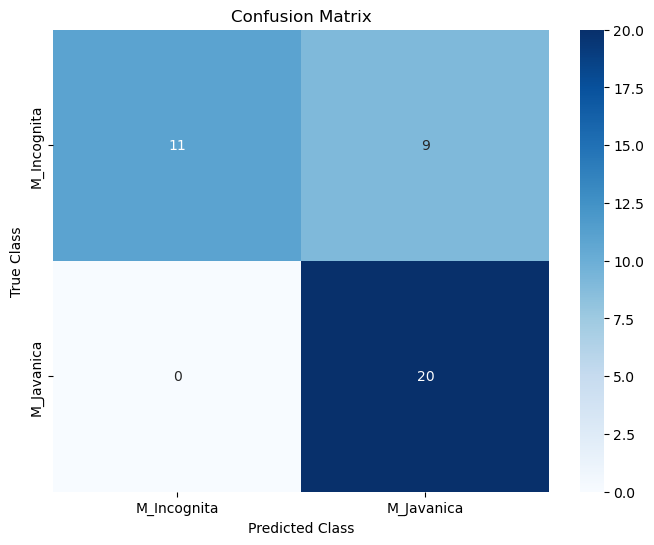

In [14]:
labels = sorted(df["original_class"].unique())

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.show()